# EDA & Preprocessing Notebook

This notebook explores:
1. Class distribution and imbalance check.
2. Random images per class.
3. Pixel intensity histograms.
4. Optional augmentation preview.



In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Point to your training and testing folders
train_path = "../data/archive/Training"
test_path  = "../data/archive/Testing"

# You can loop through each folder in the training directory:
classes = [d for d in os.listdir(train_path) if os.path.isdir(os.path.join(train_path, d))]

print("Classes in Training Folder:", classes)

train_counts = {}
for cls in classes:
    cls_dir = os.path.join(train_path, cls)
    # Count the number of image files
    num_images = sum(fname.lower().endswith(('.png', '.jpg', '.jpeg')) 
                     for fname in os.listdir(cls_dir))
    train_counts[cls] = num_images
# Repeat for test folder if needed
test_counts = {}
for cls in classes:
    cls_dir = os.path.join(test_path, cls)
    num_images = sum(fname.lower().endswith(('.png', '.jpg', '.jpeg'))
                     for fname in os.listdir(cls_dir))
    test_counts[cls] = num_images

print("\nTesting set distribution:")
for c, count in test_counts.items():
    print(f"{c}: {count} images")


Classes in Training Folder: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training set distribution:
glioma: 1321 images
meningioma: 1339 images
notumor: 1595 images
pituitary: 1457 images

Testing set distribution:
glioma: 300 images
meningioma: 306 images
notumor: 405 images
pituitary: 300 images


## 1. Class Distribution & Imbalance Check


In [13]:
# Gather classes
classes = [d for d in os.listdir(train_path) if os.path.isdir(os.path.join(train_path, d))]
print("Classes in Training Folder:", classes)

train_counts = {}
for cls in classes:
    cls_dir = os.path.join(train_path, cls)
    num_images = sum(fname.lower().endswith(('.png', '.jpg', '.jpeg')) 
                     for fname in os.listdir(cls_dir))
    train_counts[cls] = num_images

print("\nTraining set distribution:")
total_train = 0
for c, count in train_counts.items():
    print(f"{c}: {count} images")
    total_train += count

print("\nTotal training images:", total_train)
print("\nClass Imbalance Ratios (train):")
for c, count in train_counts.items():
    ratio = count / total_train * 100
    print(f"{c}: {ratio:.2f}% of training data")


Classes in Training Folder: ['glioma', 'meningioma', 'notumor', 'pituitary']

Training set distribution:
glioma: 1321 images
meningioma: 1339 images
notumor: 1595 images
pituitary: 1457 images

Total training images: 5712

Class Imbalance Ratios (train):
glioma: 23.13% of training data
meningioma: 23.44% of training data
notumor: 27.92% of training data
pituitary: 25.51% of training data


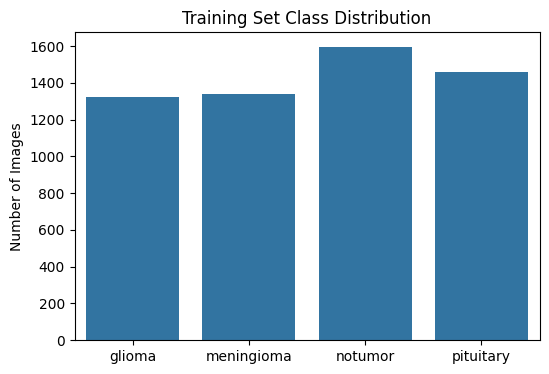

In [14]:
# Plot bar chart
labels, values = zip(*train_counts.items())
plt.figure(figsize=(6,4))
sns.barplot(x=list(labels), y=list(values))
plt.title("Training Set Class Distribution")
plt.ylabel("Number of Images")
plt.show()


## 2. Random Sample Images Per Class


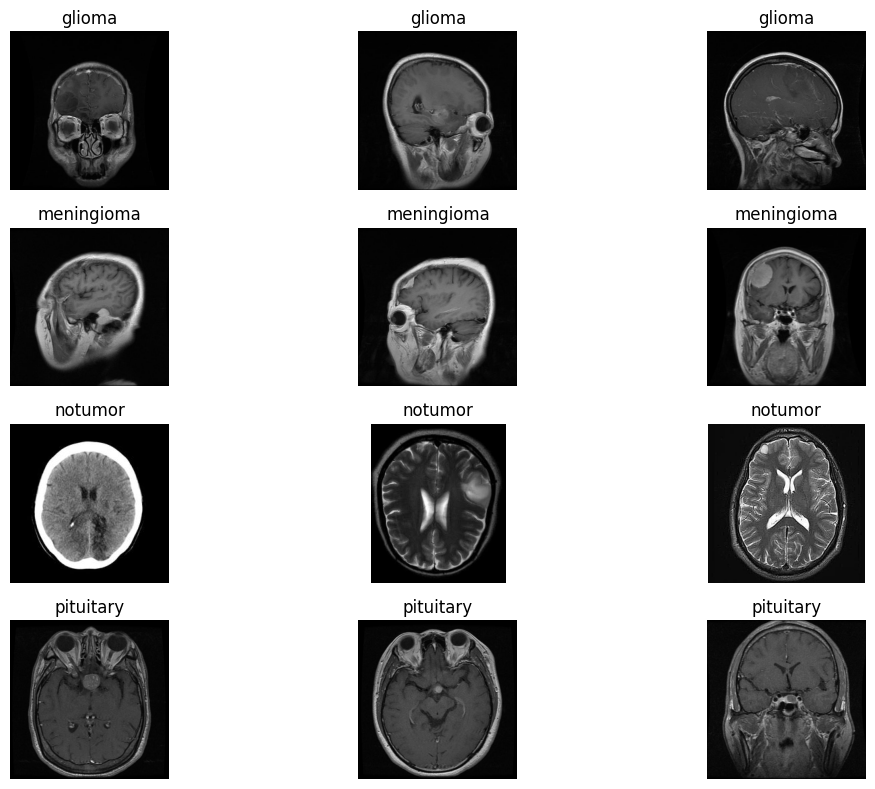

In [18]:
num_samples_per_class = 3
plt.figure(figsize=(12, 8))

for i, cls in enumerate(classes):
    cls_dir = os.path.join(train_path, cls)
    all_imgs = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    # randomly pick a few images
    sampled_imgs = random.sample(all_imgs, num_samples_per_class)

    for j, img_name in enumerate(sampled_imgs):
        img_path = os.path.join(cls_dir, img_name)
        img = Image.open(img_path).convert('L')  # grayscale

        plt.subplot(len(classes), num_samples_per_class, i*num_samples_per_class + j + 1)
        plt.imshow(img, cmap='gray')
        plt.title(f"{cls}")
        plt.axis('off')

plt.tight_layout()
plt.show()


## 3. Pixel Intensity Histograms

Let's plot how pixel values are distributed for random images. This can guide our normalization choices.


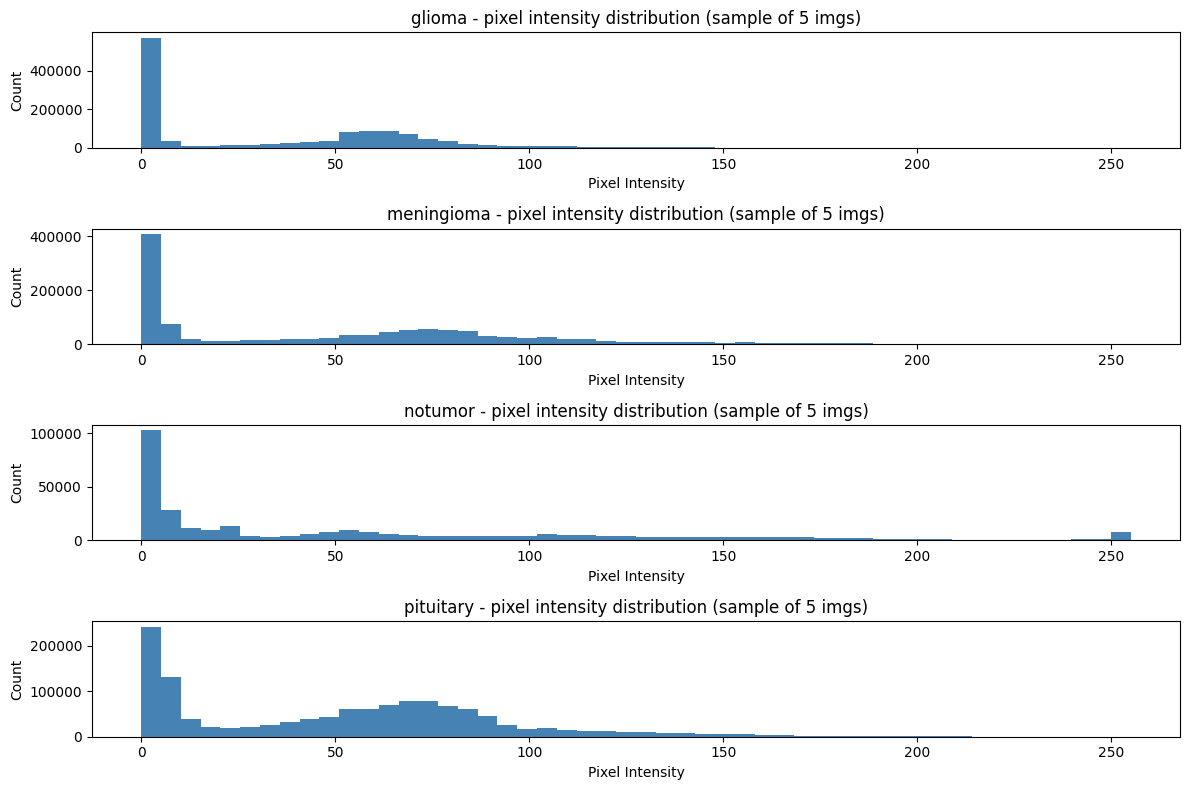

In [19]:
num_hist_images = 5  # how many images per class to do hist
plt.figure(figsize=(12, 8))

for i, cls in enumerate(classes):
    cls_dir = os.path.join(train_path, cls)
    all_imgs = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    # randomly pick images
    sampled_imgs = random.sample(all_imgs, num_hist_images)

    pixel_values = []
    for img_name in sampled_imgs:
        img_path = os.path.join(cls_dir, img_name)
        img = Image.open(img_path).convert('L')
        arr = np.array(img)
        pixel_values.extend(arr.flatten().tolist())

    # Plot histogram for this class
    plt.subplot(len(classes), 1, i+1)
    plt.hist(pixel_values, bins=50, range=(0,255), color='steelblue')
    plt.title(f"{cls} - pixel intensity distribution (sample of {num_hist_images} imgs)")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()


## 4. Optional Augmentation Preview


In [20]:
# We'll create a transform with augment=True and show a before/after.
# If you prefer, comment out if not needed.

augment_transform = create_transform(
    image_size=(128, 128),
    normalization="minmax",  # or zscore
    augment=True,  # turn on mild augmentation
    rotation_range=(0,15),
    brightness=(0.95,1.05),
    contrast=(0.95,1.05)
)

cls_test = random.choice(classes)
cls_dir_test = os.path.join(train_path, cls_test)
img_name_test = random.choice(os.listdir(cls_dir_test))
img_path_test = os.path.join(cls_dir_test, img_name_test)

original_img = Image.open(img_path_test).convert('L')
aug_tensor = augment_transform(original_img)
aug_arr = aug_tensor.squeeze().numpy()

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(original_img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(aug_arr, cmap='gray')
plt.title("Augmented + Normalized")
plt.axis('off')

plt.tight_layout()
plt.show()
print(f"Class: {cls_test}, Image: {img_name_test}")


NameError: name 'create_transform' is not defined